In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Load JUN18 Excel

excel_path = "JUN18.xlsx"

# First inspect the sheet names
xls = pd.ExcelFile(excel_path)
print("Available sheets:")
print(xls.sheet_names)


# Read the Steady State & SAOS sheet

sheet_name = "Steady State & SAOS"

# Read without header first, because rheology Excel files often
# contain multiple header rows / merged cells
raw = pd.read_excel(excel_path, sheet_name=sheet_name, header=None)

print("\nRaw sheet preview:")
print(raw.head(20))

Available sheets:
['Steady State & SAOS', 'Helton', 'Step Up Step Down', 'LAOS', 'reversal', 'Cessation ', 'SRFS', 'UDLAOS']

Raw sheet preview:
                  0            1                 2   3                 4   \
0                NaN          NaN               NaN NaN               NaN   
1   Shear Rate (1/s)  Stress (Pa)  Viscosity (Pa s) NaN  Shear Rate (1/s)   
2                0.1     0.002059           0.02059 NaN               0.1   
3                0.2      0.00401           0.02005 NaN               0.2   
4               0.35     0.007133           0.02038 NaN              0.35   
5                0.7      0.01258          0.017971 NaN               0.7   
6                  1      0.01576           0.01576 NaN                 1   
7                  2      0.02376           0.01188 NaN                 2   
8                3.5     0.033711          0.009632 NaN               3.5   
9                  7       0.0518            0.0074 NaN                 7   
10      

In [16]:
# Extract steady-state data

ss1 = raw.iloc[:, 0:3].copy()
ss2 = raw.iloc[:, 4:7].copy()

ss1.columns = ["shear_rate", "stress", "viscosity"]
ss2.columns = ["shear_rate", "stress", "viscosity"]


def clean_ss(df):

    for col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df = df.dropna()

    df = df[
        (df["shear_rate"] > 0) &
        (df["stress"] >= 0) &
        (df["viscosity"] > 0)
    ].copy()

    df = df.sort_values(
        "shear_rate"
    ).reset_index(drop=True)

    return df


ss1 = clean_ss(ss1)
ss2 = clean_ss(ss2)

print("\nSS1 number of points:", len(ss1))
print("SS2 number of points:", len(ss2))

print("\nSS1:")
print(ss1)

print("\nSS2:")
print(ss2)


SS1 number of points: 16
SS2 number of points: 16

SS1:
    shear_rate    stress  viscosity
0         0.10  0.002059   0.020590
1         0.20  0.004010   0.020050
2         0.35  0.007133   0.020380
3         0.70  0.012580   0.017971
4         1.00  0.015760   0.015760
5         2.00  0.023760   0.011880
6         3.50  0.033711   0.009632
7         7.00  0.051800   0.007400
8        10.00  0.065400   0.006540
9        20.00  0.108970   0.005449
10       35.00  0.168900   0.004826
11       70.00  0.298000   0.004257
12      100.00  0.403668   0.004037
13      200.00  0.720695   0.003603
14      350.00  1.185800   0.003388
15      700.00  2.232500   0.003189

SS2:
    shear_rate   stress  viscosity
0         0.10  0.00330   0.033000
1         0.20  0.00575   0.028750
2         0.35  0.01100   0.031429
3         0.70  0.01848   0.026400
4         1.00  0.02326   0.023260
5         2.00  0.03395   0.016975
6         3.50  0.04629   0.013226
7         7.00  0.06833   0.009761
8        1

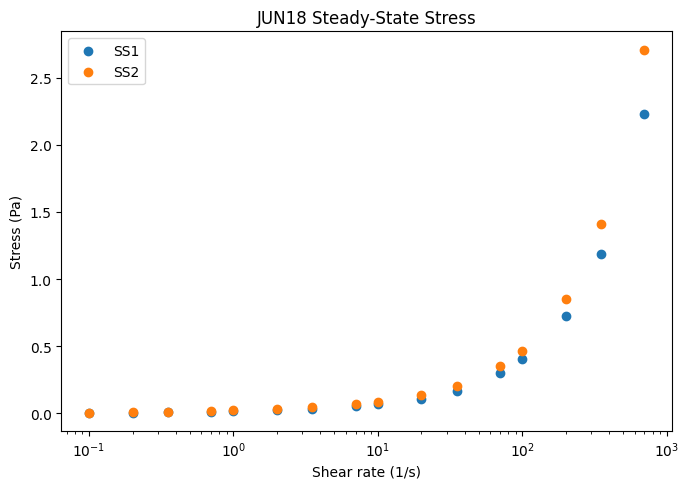

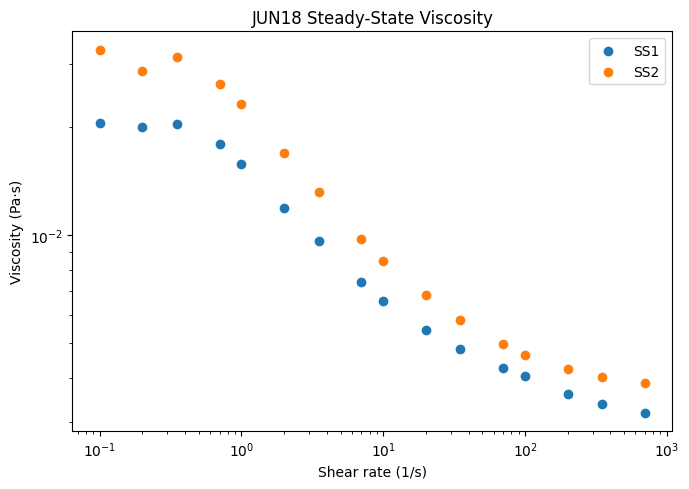

In [17]:
plt.figure(figsize=(7, 5))

plt.scatter(
    ss1["shear_rate"],
    ss1["stress"],
    label="SS1"
)

plt.scatter(
    ss2["shear_rate"],
    ss2["stress"],
    label="SS2"
)

plt.xscale("log")

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Stress (Pa)")
plt.title("JUN18 Steady-State Stress")

plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

plt.scatter(
    ss1["shear_rate"],
    ss1["viscosity"],
    label="SS1"
)

plt.scatter(
    ss2["shear_rate"],
    ss2["viscosity"],
    label="SS2"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Shear rate (1/s)")
plt.ylabel("Viscosity (Pa·s)")
plt.title("JUN18 Steady-State Viscosity")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Models

# Herschel-Bulkley:
# stress = yield_stress + K * shear_rate^n

def herschel_bulkley(
    shear_rate,
    yield_stress,
    K,
    n
):
    return (
        yield_stress
        + K * shear_rate**n
    )


# Carreau-Yasuda:
# viscosity = eta_inf + (eta_0 - eta_inf) * [1 + (lambda * shear_rate)^a]^((n - 1)/a)

def carreau_yasuda(
    shear_rate,
    eta_0,
    eta_inf,
    lambda_c,
    a,
    n
):
    return (
        eta_inf
        +
        (eta_0 - eta_inf)
        *
        (
            1
            + (lambda_c * shear_rate)**a
        )**((n - 1) / a)
    )


# Evaluation helper

def evaluate(y_true, y_pred):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, r2

In [ ]:
# Fit Herschel-Bulkley

def fit_hb(train_df):

    x = train_df["shear_rate"].values
    y = train_df["stress"].values

    initial_guess = [
        0.001,  # yield stress
        0.05,   # K
        0.7     # n
    ]

    bounds = (
        [0, 0, 0],
        [np.inf, np.inf, 2]
    )

    params, covariance = curve_fit(
        herschel_bulkley,
        x,
        y,
        p0=initial_guess,
        bounds=bounds,
        maxfev=50000
    )

    return params

In [ ]:
# Fit Carreau-Yasuda

def fit_cy(train_df):

    x = train_df["shear_rate"].values
    y = train_df["viscosity"].values

    initial_guess = [
        y.max(),  # eta_0
        y.min(),  # eta_inf
        1.0,      # lambda
        2.0,      # a
        0.5       # n
    ]

    bounds = (
        [
            0,
            0,
            0,
            0.01,
            0
        ],
        [
            np.inf,
            np.inf,
            np.inf,
            10,
            1
        ]
    )

    params, covariance = curve_fit(
        carreau_yasuda,
        x,
        y,
        p0=initial_guess,
        bounds=bounds,
        maxfev=100000
    )

    return params

In [ ]:
# Cross-validation function

def run_cross_validation(train_df,test_df,train_name,test_name):

    print("\n")
    print("=" * 60)
    print(
        f"Train on {train_name} "
        f"-> Test on {test_name}"
    )
    print("=" * 60)

    # Herschel-Bulkley

    hb_params = fit_hb(train_df)

    yield_stress, K, n = hb_params

    print("\nHerschel-Bulkley parameters:")

    print(
        f"yield stress = "
        f"{yield_stress:.6f} Pa"
    )

    print(
        f"K = {K:.6f}"
    )

    print(
        f"n = {n:.6f}"
    )

    # Training prediction

    train_stress_pred = herschel_bulkley(
        train_df["shear_rate"].values,
        *hb_params
    )

    hb_train_rmse, hb_train_r2 = evaluate(
        train_df["stress"].values,
        train_stress_pred
    )

    # Test prediction

    test_stress_pred = herschel_bulkley(
        test_df["shear_rate"].values,
        *hb_params
    )

    hb_test_rmse, hb_test_r2 = evaluate(
        test_df["stress"].values,
        test_stress_pred
    )

    print("\nHB performance:")
    print(
        f"Train RMSE = "
        f"{hb_train_rmse:.6f} Pa"
    )
    print(
        f"Train R²   = "
        f"{hb_train_r2:.6f}"
    )
    print(
        f"Test RMSE  = "
        f"{hb_test_rmse:.6f} Pa"
    )
    print(
        f"Test R²    = "
        f"{hb_test_r2:.6f}"
    )

    # Carreau-Yasuda

    cy_params = fit_cy(train_df)

    eta_0, eta_inf, lambda_c, a, n_cy = cy_params

    print("\nCarreau-Yasuda parameters:")
    print(
        f"eta_0   = "
        f"{eta_0:.6f} Pa·s"
    )
    print(
        f"eta_inf = "
        f"{eta_inf:.6f} Pa·s"
    )
    print(
        f"lambda  = "
        f"{lambda_c:.6f} s"
    )
    print(
        f"a = "
        f"{a:.6f}"
    )
    print(
        f"n = "
        f"{n_cy:.6f}"
    )

    # Training prediction

    train_visc_pred = carreau_yasuda(
        train_df["shear_rate"].values,
        *cy_params
    )

    cy_train_rmse, cy_train_r2 = evaluate(
        train_df["viscosity"].values,
        train_visc_pred
    )

    # Test prediction

    test_visc_pred = carreau_yasuda(
        test_df["shear_rate"].values,
        *cy_params
    )

    cy_test_rmse, cy_test_r2 = evaluate(
        test_df["viscosity"].values,
        test_visc_pred
    )

    print("\nCY performance:")
    print(
        f"Train RMSE = "
        f"{cy_train_rmse:.6f} Pa·s"
    )
    print(
        f"Train R²   = "
        f"{cy_train_r2:.6f}"
    )
    print(
        f"Test RMSE  = "
        f"{cy_test_rmse:.6f} Pa·s"
    )
    print(
        f"Test R²    = "
        f"{cy_test_r2:.6f}"
    )

    # Plot HB test prediction

    x_plot = np.logspace(
        np.log10(
            min(
                train_df["shear_rate"].min(),
                test_df["shear_rate"].min()
            )
        ),
        np.log10(
            max(
                train_df["shear_rate"].max(),
                test_df["shear_rate"].max()
            )
        ),
        500
    )


    plt.figure(figsize=(7, 5))

    plt.scatter(
        train_df["shear_rate"],
        train_df["stress"],
        label=f"{train_name} - training"
    )

    plt.scatter(
        test_df["shear_rate"],
        test_df["stress"],
        label=f"{test_name} - test"
    )

    plt.plot(
        x_plot,
        herschel_bulkley(
            x_plot,
            *hb_params
        ),
        label="HB model fitted on training data"
    )

    plt.xscale("log")

    plt.xlabel("Shear rate (1/s)")
    plt.ylabel("Stress (Pa)")

    plt.title(
        f"Herschel-Bulkley: "
        f"{train_name} -> {test_name}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


    # Plot CY test prediction

    plt.figure(figsize=(7, 5))

    plt.scatter(
        train_df["shear_rate"],
        train_df["viscosity"],
        label=f"{train_name} - training"
    )

    plt.scatter(
        test_df["shear_rate"],
        test_df["viscosity"],
        label=f"{test_name} - test"
    )

    plt.plot(
        x_plot,
        carreau_yasuda(
            x_plot,
            *cy_params
        ),
        label="CY model fitted on training data"
    )

    plt.xscale("log")
    plt.yscale("log")

    plt.xlabel("Shear rate (1/s)")
    plt.ylabel("Viscosity (Pa·s)")

    plt.title(
        f"Carreau-Yasuda: "
        f"{train_name} -> {test_name}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


    # Return results

    return {
        "train": train_name,
        "test": test_name,

        "HB_train_R2": hb_train_r2,
        "HB_test_R2": hb_test_r2,

        "HB_train_RMSE": hb_train_rmse,
        "HB_test_RMSE": hb_test_rmse,

        "CY_train_R2": cy_train_r2,
        "CY_test_R2": cy_test_r2,

        "CY_train_RMSE": cy_train_rmse,
        "CY_test_RMSE": cy_test_rmse
    }



Train on SS1 -> Test on SS2

Herschel-Bulkley parameters:
yield stress = 0.011345 Pa
K = 0.006115
n = 0.899410

HB performance:
Train RMSE = 0.007113 Pa
Train R²   = 0.999851
Test RMSE  = 0.138153 Pa
Test R²    = 0.961305

Carreau-Yasuda parameters:
eta_0   = 0.020386 Pa·s
eta_inf = 0.002815 Pa·s
lambda  = 1.767985 s
a = 5.045754
n = 0.471867

CY performance:
Train RMSE = 0.000118 Pa·s
Train R²   = 0.999673
Test RMSE  = 0.005781 Pa·s
Test R²    = 0.697030


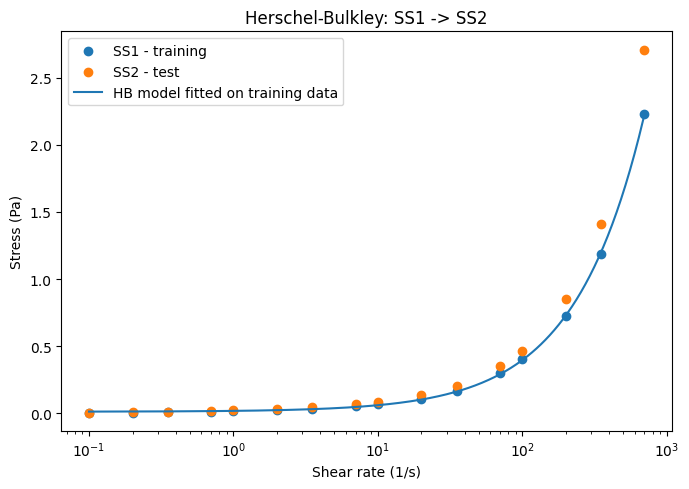

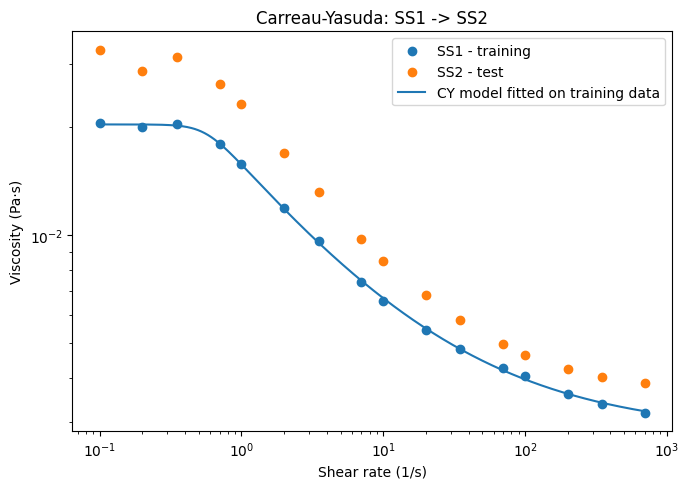



Train on SS2 -> Test on SS1

Herschel-Bulkley parameters:
yield stress = 0.020844 Pa
K = 0.006111
n = 0.928617

HB performance:
Train RMSE = 0.012066 Pa
Train R²   = 0.999705
Test RMSE  = 0.137812 Pa
Test R²    = 0.944060

Carreau-Yasuda parameters:
eta_0   = 0.031455 Pa·s
eta_inf = 0.003438 Pa·s
lambda  = 1.622017 s
a = 2.840086
n = 0.388681

CY performance:
Train RMSE = 0.000780 Pa·s
Train R²   = 0.994487
Test RMSE  = 0.005730 Pa·s
Test R²    = 0.235270


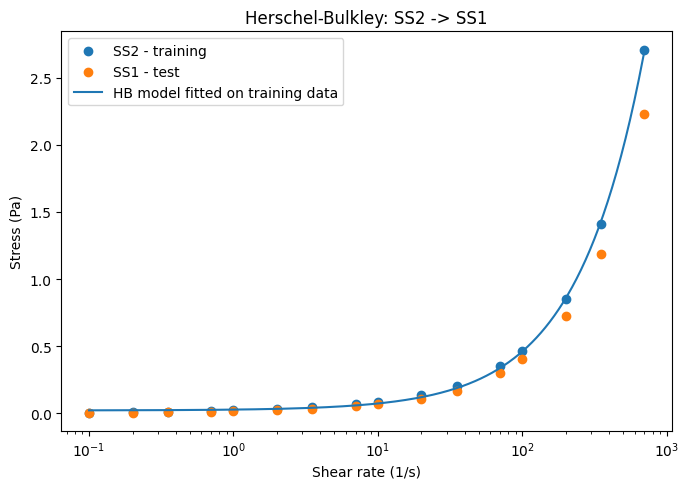

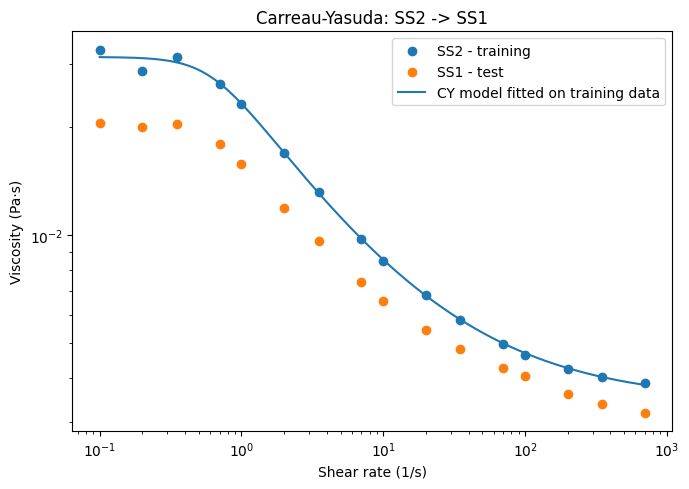



CROSS-VALIDATION SUMMARY
train test  HB_train_R2  HB_test_R2  HB_train_RMSE  HB_test_RMSE  CY_train_R2  CY_test_R2  CY_train_RMSE  CY_test_RMSE
  SS1  SS2     0.999851    0.961305       0.007113      0.138153     0.999673     0.69703       0.000118      0.005781
  SS2  SS1     0.999705    0.944060       0.012066      0.137812     0.994487     0.23527       0.000780      0.005730


In [ ]:
# Run both directions

result_1 = run_cross_validation(
    ss1,
    ss2,
    "SS1",
    "SS2"
)

result_2 = run_cross_validation(
    ss2,
    ss1,
    "SS2",
    "SS1"
)

# Summary

results = pd.DataFrame(
    [
        result_1,
        result_2
    ]
)

print("\n")
print("=" * 60)
print("CROSS-VALIDATION SUMMARY")
print("=" * 60)

print(results.to_string(index=False))